# Zadanie 3 Extra — DeepWeeds: wiarygodność ewaluacji

**Pytanie badawcze:** czy wynik modelu na opublikowanym podziale DeepWeeds odzwierciedla rozpoznawanie gatunków chwastów, czy może jest częściowo zawyżony przez bardzo podobne ujęcia obecne w zbiorach treningowym i testowym?

Twoim celem nie jest pobicie modelu bazowego. Masz zaprojektować i przeprowadzić badanie, które pozwoli ocenić wiarygodność jego ewaluacji. Równie wartościowy jest wynik potwierdzający hipotezę, jak i poprawnie uzasadniony wynik, który jej nie potwierdza.

In [1]:
# Importy i ustawienia
import json
import platform
import sys
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torchvision
from huggingface_hub import hf_hub_download, snapshot_download
from PIL import Image
from safetensors.torch import load_file
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn
from torchvision import transforms

RS = 42                                    # ziarno losowości
torch.manual_seed(RS)
pd.set_option("display.width", 200)

In [ ]:
DATA_DIR = Path("data/zadanie-3")
MODEL_DIR = Path("models/zadanie-3-model-bazowy")
DATA_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

images_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-3",
    filename="original/images.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
dataset_snapshot = snapshot_download(
    repo_id="AI-MED-AGH/Recruitment-Task-3",
    repo_type="dataset",
    allow_patterns=["labels/*.csv"],
    local_dir=DATA_DIR,
)
model_snapshot = snapshot_download(
    repo_id="AI-MED-AGH/Recruitment-Task-3-Model",
    local_dir=MODEL_DIR,
)
with ZipFile(images_path) as archive:
    archive.extractall(DATA_DIR / "images")

print(f"Dane: {dataset_snapshot}")
print(f"Model bazowy: {model_snapshot}")

Dane: C:\Users\papie\Rekrutacja-AI-Med-2026-2027\Zadanie-3\data\zadanie-3
Model bazowy: C:\Users\papie\Rekrutacja-AI-Med-2026-2027\Zadanie-3\models\zadanie-3-model-bazowy


## Najważniejsze zasady

- Korzystaj z opublikowanego **foldu 0**: `train_subset0.csv`, `val_subset0.csv` i `test_subset0.csv`. We wszystkich porównaniach zachowaj ten sam zbiór testowy.
- Sposób mierzenia podobieństwa i jego próg ustal na danych treningowych i walidacyjnych, zanim przeanalizujesz wyniki testowe.
- Główną metryką jest **macro-F1**. Pokaż również wyniki dla poszczególnych klas.
- We wszystkich wariantach użyj tego samego modelu, preprocessingu i procedury treningowej.
- Zadbaj o odtwarzalność: zapisz najważniejsze ustawienia, ziarno losowe i wersje bibliotek.

## A — Hipoteza i plan badania

Przeczytaj oryginalną publikację DeepWeeds oraz co najmniej jedno dodatkowe źródło dotyczące duplikatów lub zależnych obserwacji w ewaluacji modeli. Krótko wyjaśnij, dlaczego podobne ujęcia w treningu i teście mogą zawyżać wynik.

Zapisz jedną hipotezę: usunięcie z treningu obrazów bardzo podobnych do testowych obniży wynik bardziej niż usunięcie takiej samej liczby losowych obrazów. Przed eksperymentem określ, jak duża różnica będzie dla Ciebie istotna praktycznie.

Uruchom dostarczony checkpoint, aby sprawdzić wczytywanie danych i inferencję. Jest to celowo słaby model techniczny. Do właściwego eksperymentu wybierz jeden rozsądny model na podstawie zbiorów treningowego i walidacyjnego.

### Dlaczego podobne ujęcia mogą zawyżać wynik
DeepWeeds (Olsen i in., 2019) to 17 509 zdjęć z ośmiu miejsc w Australii, robionych seriami
podczas przejść przez teren. Zbiór podzielono **losowo** na 60% treningu, 20% walidacji i 20% testu.
Zdjęcia z jednego przejścia, zrobione kilka sekund po sobie, mogą pokazywać tę samą roślinę,
więc prawie identyczne ujęcia trafiają jednocześnie do treningu i testu. Model może wtedy
rozpoznać zdjęcie testowe, bo widział jego "bliźniaka", a nie dlatego, że nauczył się gatunku.
Barz i Denzler (2020) znaleźli takie prawie duplikaty dla 3,3% testu CIFAR-10 i 10% CIFAR-100,
a po ich wymianie błąd modeli wzrósł.

**Hipoteza:** usunięcie z treningu zdjęć bardzo podobnych do testowych obniży macro F1 na teście
bardziej niż usunięcie tej samej liczby losowych zdjęć (przy tych samych liczebnościach klas).

**Kryterium ustalone przed eksperymentem:** Δ = macro F1 (kontrolny) minus macro F1 (oczyszczony).
Hipoteza jest potwierdzona, jeśli Δ ≥ 0,02 i dolna granica 95% przedziału ufności Δ jest większa
od zera. Różnicę poniżej 0,02 uznaję za praktycznie nieistotną.

**Plan:** 1. sprawdzić checkpoint, 2. wybrać model na train i val, 3. ustalić próg podobieństwa
na train i val, 4. zbudować trzy warianty treningu, 5. porównać je z oceną niepewności.

In [2]:
# A1. Ustawienia i wersje (odtwarzalność)
DATA_DIR, MODEL_DIR = Path("data/zadanie-3"), Path("models/zadanie-3-model-bazowy")
print("fold 0 | ziarno 42 | cechy: ResNet34 ImageNet (bez douczania) | klasyfikator: regresja logistyczna")
print("Python", platform.python_version(), "| torch", torch.__version__, "| torchvision", torchvision.__version__,
      "| scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

fold 0 | ziarno 42 | cechy: ResNet34 ImageNet (bez douczania) | klasyfikator: regresja logistyczna
Python 3.13.16 | torch 2.14.0+cu130 | torchvision 0.29.0+cu130 | scikit-learn 1.9.1 | numpy 2.5.3 | pandas 3.0.5


In [3]:
# A2. Fold 0 i klasy
IMG_DIR = DATA_DIR / "images"
train, val, test = [pd.read_csv(DATA_DIR / f"labels/{s}_subset0.csv") for s in ["train", "val", "test"]]
gatunki = pd.read_csv(DATA_DIR / "labels/labels.csv")
KLASY = gatunki.groupby("Label")["Species"].agg(lambda s: s.mode()[0]).tolist()   # numer klasy -> gatunek
liczebnosc = pd.DataFrame({"train": train.Label.value_counts(), "val": val.Label.value_counts(),
                           "test": test.Label.value_counts()}).sort_index()
liczebnosc.index = KLASY
print(liczebnosc)
print("config.json modelu bazowego:", json.load(open(MODEL_DIR / "config.json"))["class_names"])

                train   val  test
Chinee apple      675   225   226
Lantana           637   213   213
Parkinsonia       618   206   207
Parthenium        613   204   205
Prickly acacia    637   212   213
Rubber vine       605   202   202
Siam weed         644   215   215
Snake weed        609   203   204
Negative         5463  1821  1822
config.json modelu bazowego: ['Chinee apple', 'Lantana', 'Negative', 'Parkinsonia', 'Parthenium', 'Prickly acacia', 'Rubber vine', 'Siam weed', 'Snake weed']


In [4]:
# A3. Uruchomienie dostarczonego checkpointu
sys.path.insert(0, str(MODEL_DIR))                     # pliki model.py i data.py modelu bazowego
from data import build_comparison_transforms           # noqa: E402
from model import SmallDeepWeedsCNN                     # noqa: E402

bazowy = SmallDeepWeedsCNN(num_classes=9, in_channels=1)
bazowy.load_state_dict(load_file(str(MODEL_DIR / "model.safetensors")), strict=True)
bazowy.eval()
przeksztalc = build_comparison_transforms()["bad_test"]
with torch.inference_mode():
    pred_bazowy = np.concatenate([
        bazowy(torch.stack([przeksztalc(Image.open(IMG_DIR / f)) for f in test.Filename[i:i + 128]])).argmax(1).numpy()
        for i in range(0, len(test), 128)])
print(f"model bazowy: macro F1 {f1_score(test.Label, pred_bazowy, average='macro'):.4f}, "
      f"accuracy {accuracy_score(test.Label, pred_bazowy):.4f}, klasa Negative w {np.mean(pred_bazowy == 8):.0%} odpowiedzi")

model bazowy: macro F1 0.2066, accuracy 0.5421, klasa Negative w 84% odpowiedzi


### Wnioski z części A
- **Fold 0:** train 10 501, walidacja 3 501, test 3 507 zdjęć, bez wspólnych plików. W każdym
  podziale klasa Negative (brak chwastu) to około 52% zdjęć, każdy z 8 gatunków po około 6%.
- **Checkpoint:** model bazowy dał na teście dokładnie opublikowany wynik (macro F1 0,2066,
  accuracy 0,5421) i w 84% przypadków odpowiada klasą Negative. Wczytywanie danych i inferencja
  działają więc poprawnie.
- **Znalezione niezgodności:** config.json modelu bazowego podaje nazwy klas alfabetycznie,
  przez co od numeru 2 nie zgadzają się z labels.csv (na przykład 2 to Parkinsonia, a nie Negative).
  Nazwy klas biorę z labels.csv. Według README modelu bazowego jedno zdjęcie (20170714-110407-3.jpg) ma w labels.csv inną
  etykietę niż w pliku foldu 0; używam etykiet z plików foldu, jak model bazowy.
- **Wybór modelu:** zamrożona sieć ResNet34 (wagi ImageNet) jako ekstraktor cech i regresja
  logistyczna na tych cechach. Trzeba wytrenować model kilkanaście razy (3 warianty, w tym
  10 losowań kontrolnych), a pełny trening sieci na CPU byłby zbyt kosztowny; polecenie dopuszcza
  zamrożone cechy. Na walidacji najlepsze było C = 0,01 bez wag klas (macro F1 0,705).
  Ten sam model i ta sama procedura są użyte we wszystkich wariantach.

## B — Eksperyment

Wybierz i uzasadnij jeden sposób wykrywania podobnych obrazów, na przykład perceptual hash albo odległość embeddingów. Ustal próg na danych treningowych i walidacyjnych, a następnie ręcznie sprawdź przykładowe pary uznane za podobne i niepodobne.

Sprawdź, ile obrazów testowych ma bardzo podobny odpowiednik w zbiorze treningowym i jak zjawisko rozkłada się między klasami. Następnie przygotuj trzy warianty zbioru treningowego:

1. **oryginalny** — pełny trening z foldu 0;
2. **oczyszczony** — bez obrazów treningowych podobnych do testowych;
3. **kontrolny** — bez takiej samej liczby losowych obrazów, z zachowaniem podobnych liczebności klas.

Wytrenuj ten sam model w każdym wariancie i oceń wszystkie wersje na niezmienionym zbiorze testowym. Jeżeli pełny trening jest zbyt kosztowny, możesz użyć lekkiego modelu albo zamrożonych cech — jednakowo we wszystkich trzech wariantach.

In [5]:
# B1. Cechy zdjęć z wstępnie wytrenowanej sieci ResNet34 (zapisywane do pliku)
# Zamrożona sieć zamienia każde zdjęcie na wektor 512 liczb. Liczenie trwa około 30 minut na CPU,
# więc wynik zapisuję i przy kolejnym uruchomieniu tylko go wczytuję.
PLIK_CECH = DATA_DIR / "cechy_resnet34.npz"
if not PLIK_CECH.exists():
    siec = torchvision.models.resnet34()
    siec.load_state_dict(torch.hub.load_state_dict_from_url(
        "https://github.com/huggingface/pytorch-image-models/releases/download/v0.1-weights/resnet34-43635321.pth",
        model_dir=str(DATA_DIR / "wagi"), check_hash=True))
    siec.fc = nn.Identity()                            # bez ostatniej warstwy zostaje wektor 512 cech
    siec.eval()
    przygotuj = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                                    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    nazwy = sorted(gatunki.Filename)
    with torch.inference_mode():
        wektory = [siec(torch.stack([przygotuj(Image.open(IMG_DIR / f).convert("RGB")) for f in nazwy[i:i + 64]])).numpy()
                   for i in range(0, len(nazwy), 64)]
    np.savez_compressed(PLIK_CECH, nazwy=np.array(nazwy), cechy=np.concatenate(wektory))

zapis = np.load(PLIK_CECH)
indeks = {n: i for i, n in enumerate(zapis["nazwy"])}
X_train, X_val, X_test = [zapis["cechy"][[indeks[f] for f in d.Filename]] for d in [train, val, test]]
y_train, y_val, y_test = train.Label.to_numpy(), val.Label.to_numpy(), test.Label.to_numpy()

In [6]:
# B2. Wybór modelu na treningu i walidacji
def nowy_model(C=0.01, wagi=None):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight=wagi, max_iter=3000))


for C in [0.01, 0.1, 1.0]:
    for wagi in [None, "balanced"]:
        f1 = f1_score(y_val, nowy_model(C, wagi).fit(X_train, y_train).predict(X_val), average="macro")
        print(f"C = {C:<5} wagi klas = {str(wagi):9s} macro F1 val = {f1:.4f}")

C = 0.01  wagi klas = None      macro F1 val = 0.7047


C = 0.01  wagi klas = balanced  macro F1 val = 0.6554


C = 0.1   wagi klas = None      macro F1 val = 0.7011


C = 0.1   wagi klas = balanced  macro F1 val = 0.6640


C = 1.0   wagi klas = None      macro F1 val = 0.6643


C = 1.0   wagi klas = balanced  macro F1 val = 0.6375


próg 0.9448; zdjęcia val z bliźniakiem w train: 2.8%
pary z tej samej sesji (do 10 min): nad progiem 49%, pod progiem 26%


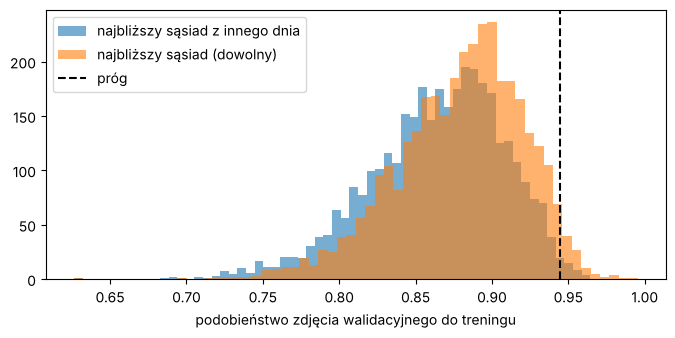

In [7]:
# B3. Podobieństwo zdjęć (cosinus cech) i próg ustalony na train i val
# Cosinus 1 = identyczny "kierunek" cech. Próg: 99. percentyl podobieństwa zdjęć walidacyjnych
# do najbliższego zdjęcia treningowego z INNEGO dnia (czyli na pewno innego ujęcia).
def normuj(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True)


def czas(df):                                          # nazwa pliku to data i godzina zdjęcia
    return pd.to_datetime(df.Filename.str[:15], format="%Y%m%d-%H%M%S")


podob_val = normuj(X_val) @ normuj(X_train).T
najblizszy, max_val = podob_val.argmax(1), podob_val.max(1)
inny_dzien = czas(val).dt.date.to_numpy()[:, None] != czas(train).dt.date.to_numpy()[None, :]
max_inny_dzien = np.where(inny_dzien, podob_val, -1).max(1)
PROG = np.quantile(max_inny_dzien, 0.99)
nad = max_val >= PROG
blisko = (czas(val).to_numpy() - czas(train).to_numpy()[najblizszy]) <= np.timedelta64(10, "m")
blisko &= (czas(train).to_numpy()[najblizszy] - czas(val).to_numpy()) <= np.timedelta64(10, "m")
print(f"próg {PROG:.4f}; zdjęcia val z bliźniakiem w train: {nad.mean():.1%}")
print(f"pary z tej samej sesji (do 10 min): nad progiem {blisko[nad].mean():.0%}, pod progiem {blisko[~nad].mean():.0%}")

plt.figure(figsize=(8, 3.5))
plt.hist(max_inny_dzien, bins=60, alpha=0.6, label="najbliższy sąsiad z innego dnia")
plt.hist(max_val, bins=60, alpha=0.6, label="najbliższy sąsiad (dowolny)")
plt.axvline(PROG, color="k", ls="--", label="próg")
plt.xlabel("podobieństwo zdjęcia walidacyjnego do treningu"); plt.legend()
plt.show()

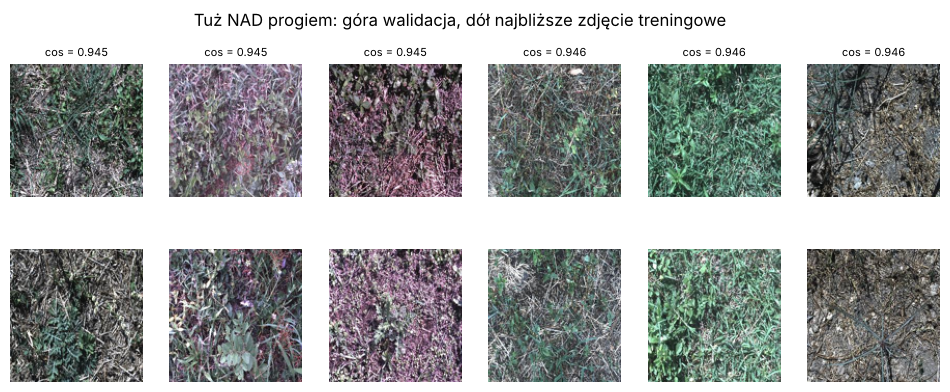

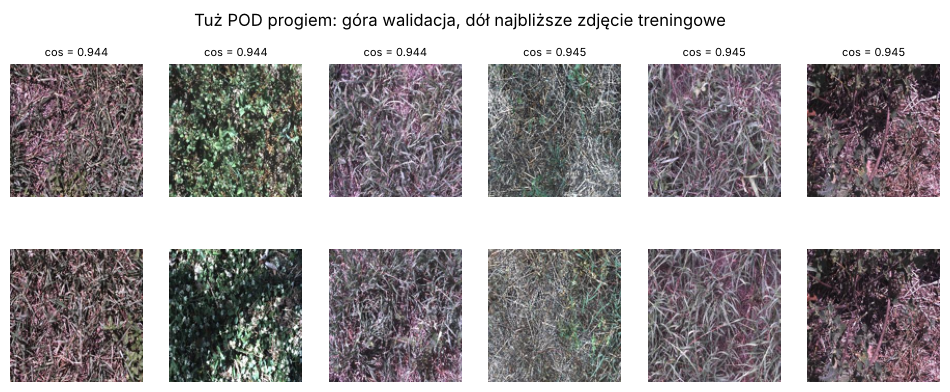

In [8]:
# B4. Ręczne sprawdzenie: pary tuż nad i tuż pod progiem
def pokaz_pary(pary, tytul):
    fig, axes = plt.subplots(2, len(pary), figsize=(2 * len(pary), 4.4))
    for k, (a, b, s) in enumerate(pary):
        for w, plik in enumerate([a, b]):
            axes[w, k].imshow(Image.open(IMG_DIR / plik).resize((128, 128)))
            axes[w, k].axis("off")
        axes[0, k].set_title(f"cos = {s:.3f}", fontsize=8)
    plt.suptitle(tytul)
    plt.show()


po_kolei = np.argsort(max_val)
for wybrane, opis in [([i for i in po_kolei if nad[i]][:6], "NAD progiem"), ([i for i in po_kolei if not nad[i]][-6:], "POD progiem")]:
    pokaz_pary([(val.Filename[i], train.Filename[najblizszy[i]], max_val[i]) for i in wybrane],
               f"Tuż {opis}: góra walidacja, dół najbliższe zdjęcie treningowe")

zdjęcia testowe z bliźniakiem: 123 z 3507 (3.5%)
Chinee apple      0.000
Lantana           0.005
Parkinsonia       0.039
Parthenium        0.112
Prickly acacia    0.042
Rubber vine       0.000
Siam weed         0.009
Snake weed        0.005
Negative          0.043
dtype: float64


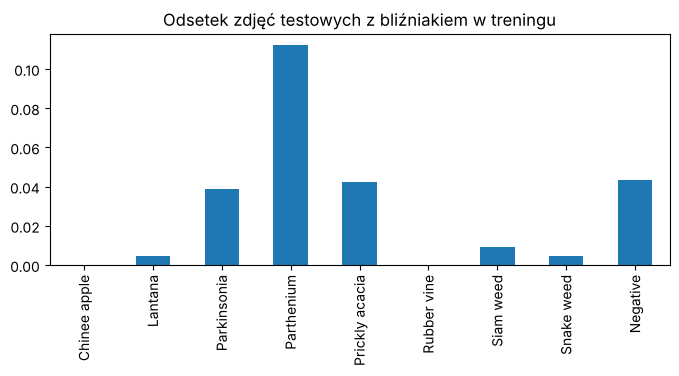

In [9]:
# B5. Zdjęcia testowe z bliźniakiem w treningu
podob_test = normuj(X_test) @ normuj(X_train).T
ma_blizniaka = podob_test.max(1) >= PROG
print(f"zdjęcia testowe z bliźniakiem: {ma_blizniaka.sum()} z {len(test)} ({ma_blizniaka.mean():.1%})")
na_klase = pd.Series(np.bincount(y_test[ma_blizniaka], minlength=9) / np.bincount(y_test), index=KLASY)
print(na_klase.round(3))
na_klase.plot(kind="bar", figsize=(8, 3), title="Odsetek zdjęć testowych z bliźniakiem w treningu")
plt.show()

In [10]:
# B6. Trzy warianty treningu i ten sam model dla każdego
# oczyszczony: bez zdjęć treningowych podobnych (>= próg) do dowolnego zdjęcia testowego,
# kontrolny: bez tylu samych losowych zdjęć w każdej klasie (10 losowań).
usun = (podob_test >= PROG).any(axis=0)
ile_na_klase = np.bincount(y_train[usun], minlength=9)
print(f"usuwane zdjęcia treningowe: {usun.sum()}", dict(zip(KLASY, ile_na_klase.tolist())))


def kontrolny(ziarno):
    los = np.random.default_rng(ziarno)
    zostaje = np.ones(len(train), dtype=bool)
    for k in range(9):
        zostaje[los.choice(np.where(y_train == k)[0], size=ile_na_klase[k], replace=False)] = False
    return zostaje


warianty = {"oryginalny": np.ones(len(train), dtype=bool), "oczyszczony": ~usun}
warianty.update({f"kontrolny_{z}": kontrolny(z) for z in range(10)})
pred = {}
for nazwa, zostaje in warianty.items():
    pred[nazwa] = nowy_model().fit(X_train[zostaje], y_train[zostaje]).predict(X_test)
    print(f"{nazwa:12s} trening {zostaje.sum()} zdjęć, macro F1 test {f1_score(y_test, pred[nazwa], average='macro'):.4f}")

usuwane zdjęcia treningowe: 161 {'Chinee apple': 0, 'Lantana': 1, 'Parkinsonia': 13, 'Parthenium': 37, 'Prickly acacia': 12, 'Rubber vine': 0, 'Siam weed': 2, 'Snake weed': 1, 'Negative': 95}


oryginalny   trening 10501 zdjęć, macro F1 test 0.7064


oczyszczony  trening 10340 zdjęć, macro F1 test 0.7046


kontrolny_0  trening 10340 zdjęć, macro F1 test 0.7036


kontrolny_1  trening 10340 zdjęć, macro F1 test 0.7058


kontrolny_2  trening 10340 zdjęć, macro F1 test 0.7047


... (3 outputs left out)

kontrolny_6  trening 10340 zdjęć, macro F1 test 0.7054


kontrolny_7  trening 10340 zdjęć, macro F1 test 0.7004


kontrolny_8  trening 10340 zdjęć, macro F1 test 0.7017


kontrolny_9  trening 10340 zdjęć, macro F1 test 0.7040


### Wnioski z części B
- **Metoda:** podobieństwo cosinusowe cech ResNet34, jak u Barza i Denzlera (2020). Działa lepiej
  niż porównywanie pikseli, bo toleruje małe przesunięcia kadru i zmiany światła między kolejnymi
  zdjęciami.
- **Próg 0,9448** ustaliłem tylko na treningu i walidacji: to 99. percentyl podobieństwa
  zdjęć walidacyjnych do najbliższego zdjęcia treningowego **z innego dnia**, czyli do zdjęcia,
  które na pewno jest innym ujęciem. Powyżej progu znalazło się 2,8% zdjęć walidacyjnych.
  Pary nad progiem w 49% pochodzą z tej samej sesji (do 10 minut odstępu), pary pod progiem
  tylko w 26%, więc próg rzeczywiście wychwytuje ujęcia z tego samego miejsca i czasu.
- **Ręczne sprawdzenie:** pary tuż nad progiem to zwykle ten sam typ roślinności i oświetlenia,
  ale nie ta sama roślina. Pary tuż pod progiem wyglądają podobnie. Prawdziwe prawie duplikaty
  (ta sama roślina, lekko przesunięty kadr) mają podobieństwo powyżej około 0,97. Próg jest więc
  **liberalny**: obejmuje prawie duplikaty i dodatkowo bardzo podobne sceny.
- **Test:** 123 z 3 507 zdjęć testowych (3,5%) ma bliźniaka w treningu, a tylko 8 ma podobieństwo
  powyżej 0,97. Rozkład jest nierówny: Parthenium 11,2%, Negative 4,3%, Prickly acacia 4,2%,
  Parkinsonia 3,9%, Chinee apple i Rubber vine 0%.
- **Warianty:** oczyszczony usuwa 161 zdjęć treningowych (1,5%), głównie Negative (95)
  i Parthenium (37). Kontrolny usuwa w każdej klasie tyle samo losowych zdjęć, w 10 losowaniach.

## C — Analiza dowodów i wniosek

Porównaj macro-F1 i wyniki klas dla trzech wariantów. Najważniejsza jest różnica między wariantem oczyszczonym i kontrolnym, ponieważ oba zawierają mniej danych. Dodaj prostą ocenę niepewności, na przykład przedział ufności albo powtórzenie eksperymentu dla kilku ziaren.

Pokaż przykłady podobnych par i reprezentatywne błędy. Sprawdź również, czy model częściej poprawnie klasyfikuje obrazy testowe mające podobny odpowiednik w treningu. Pamiętaj, że taki związek sam w sobie nie dowodzi zapamiętywania obrazów.

Zakończ odpowiedzią na pytanie badawcze i odnieś ją do ustalonego wcześniej kryterium. Wynik niepotwierdzający hipotezy jest poprawnym wynikiem. Wskaż najważniejsze ograniczenia badania, w tym fakt, że eksperyment dotyczy jednego foldu i nie zastępuje testu na danych z nowego miejsca lub czasu.

                          macro F1  accuracy
oryginalny                  0.7064    0.7779
oczyszczony                 0.7046    0.7764
kontrolny (średnia z 10)    0.7037    0.7758
                oryginalny  oczyszczony  kontrolny
Chinee apple        0.6422       0.6373     0.6366
Lantana             0.7010       0.6942     0.6994
Parkinsonia         0.8460       0.8439     0.8418
Parthenium          0.6429       0.6446     0.6347
Prickly acacia      0.7677       0.7659     0.7655
Rubber vine         0.7460       0.7447     0.7445
Siam weed           0.6357       0.6357     0.6357
Snake weed          0.5299       0.5299     0.5301
Negative            0.8462       0.8453     0.8446


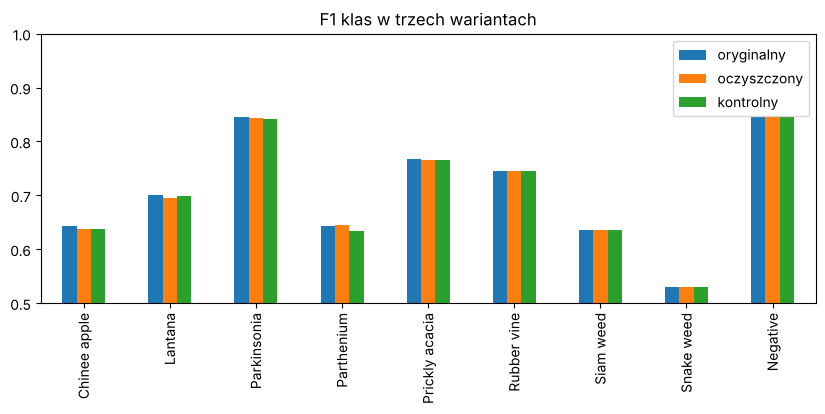

In [11]:
# C1. Tabela i wykres porównawczy
kontrolne = [f"kontrolny_{z}" for z in range(10)]
macro = lambda p: f1_score(y_test, p, average="macro")
tabela = pd.DataFrame({
    "macro F1": [macro(pred["oryginalny"]), macro(pred["oczyszczony"]), np.mean([macro(pred[k]) for k in kontrolne])],
    "accuracy": [accuracy_score(y_test, pred["oryginalny"]), accuracy_score(y_test, pred["oczyszczony"]),
                 np.mean([accuracy_score(y_test, pred[k]) for k in kontrolne])],
}, index=["oryginalny", "oczyszczony", "kontrolny (średnia z 10)"])
print(tabela.round(4))

f1_klas = pd.DataFrame({"oryginalny": f1_score(y_test, pred["oryginalny"], average=None),
                        "oczyszczony": f1_score(y_test, pred["oczyszczony"], average=None),
                        "kontrolny": np.mean([f1_score(y_test, pred[k], average=None) for k in kontrolne], axis=0)},
                       index=KLASY)
print(f1_klas.round(4))
f1_klas.plot(kind="bar", figsize=(10, 3.5), ylim=(0.5, 1), title="F1 klas w trzech wariantach")
plt.show()

Δ = -0.0009, 95% przedział ufności [-0.0037, 0.0019]
hipoteza NIEPOTWIERDZONA (kryterium: Δ >= 0,02 i dolna granica > 0)


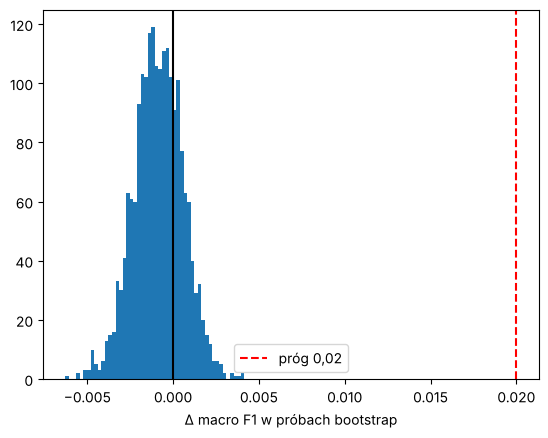

In [12]:
# C2. Niepewność: bootstrap (2000 losowań zdjęć testowych ze zwracaniem)
los = np.random.default_rng(RS)
delta = []
for _ in range(2000):
    i = los.integers(0, len(y_test), len(y_test))
    f1_ocz = f1_score(y_test[i], pred["oczyszczony"][i], average="macro")
    delta.append(np.mean([f1_score(y_test[i], pred[k][i], average="macro") for k in kontrolne]) - f1_ocz)
DELTA = tabela.loc["kontrolny (średnia z 10)", "macro F1"] - tabela.loc["oczyszczony", "macro F1"]
dol, gora = np.quantile(delta, [0.025, 0.975])
print(f"Δ = {DELTA:.4f}, 95% przedział ufności [{dol:.4f}, {gora:.4f}]")
print("hipoteza", "POTWIERDZONA" if DELTA >= 0.02 and dol > 0 else "NIEPOTWIERDZONA", "(kryterium: Δ >= 0,02 i dolna granica > 0)")

plt.hist(delta, bins=50)
plt.axvline(0, color="k"); plt.axvline(0.02, color="r", ls="--", label="próg 0,02")
plt.xlabel("Δ macro F1 w próbach bootstrap"); plt.legend()
plt.show()

In [13]:
# C3. Accuracy dla zdjęć testowych z bliźniakiem i bez
trafne = pred["oryginalny"] == y_test
print(f"z bliźniakiem: {trafne[ma_blizniaka].mean():.3f} ({ma_blizniaka.sum()} zdjęć), "
      f"bez bliźniaka: {trafne[~ma_blizniaka].mean():.3f}")
print(pd.DataFrame({"z bliźniakiem": [trafne[(y_test == k) & ma_blizniaka].mean() for k in range(9)],
                    "bez bliźniaka": [trafne[(y_test == k) & ~ma_blizniaka].mean() for k in range(9)],
                    "liczba z bliźniakiem": [((y_test == k) & ma_blizniaka).sum() for k in range(9)]},
                   index=KLASY).round(3))

z bliźniakiem: 0.862 (123 zdjęć), bez bliźniaka: 0.775
                z bliźniakiem  bez bliźniaka  liczba z bliźniakiem
Chinee apple              NaN          0.580                     0
Lantana                 0.000          0.675                     1
Parkinsonia             0.875          0.834                     8
Parthenium              0.870          0.533                    23
Prickly acacia          0.667          0.740                     9
Rubber vine               NaN          0.698                     0
Siam weed               0.500          0.573                     2
Snake weed              0.000          0.458                     1
Negative                0.911          0.905                    79


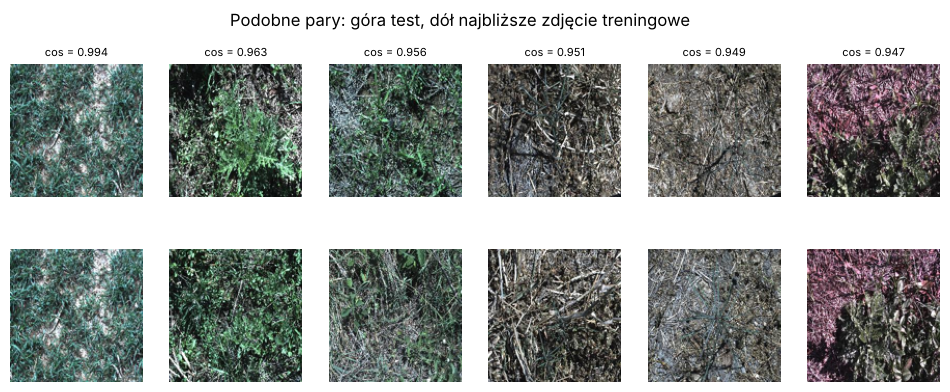

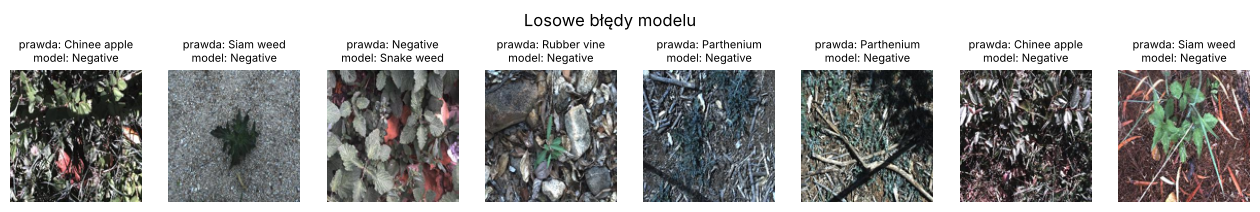

In [14]:
# C4. Przykłady podobnych par i błędów
pary = np.where(ma_blizniaka)[0]
pary = pary[np.argsort(-podob_test.max(1)[pary])][::len(pary) // 6][:6]
pokaz_pary([(test.Filename[i], train.Filename[podob_test[i].argmax()], podob_test[i].max()) for i in pary],
           "Podobne pary: góra test, dół najbliższe zdjęcie treningowe")

fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, i in zip(axes, np.random.default_rng(RS).choice(np.where(~trafne)[0], 8, replace=False)):
    ax.imshow(Image.open(IMG_DIR / test.Filename[i]).resize((128, 128)))
    ax.set_title(f"prawda: {KLASY[y_test[i]]}\nmodel: {KLASY[pred['oryginalny'][i]]}", fontsize=8)
    ax.axis("off")
plt.suptitle("Losowe błędy modelu")
plt.show()

### Wnioski
**Wyniki (macro F1 na tym samym teście):**

| wariant | zdjęcia treningowe | macro F1 | accuracy |
|---|---|---|---|
| oryginalny | 10 501 | 0,7064 | 0,7779 |
| oczyszczony | 10 340 | 0,7046 | 0,7764 |
| kontrolny (średnia z 10 losowań) | 10 340 | 0,7037 (od 0,7004 do 0,7058) | 0,7758 |

- **Δ = kontrolny minus oczyszczony = −0,0009**, 95% przedział ufności (bootstrap) od −0,0037
  do 0,0019. Δ jest daleko poniżej ustalonego progu 0,02, a przedział obejmuje zero.
  **Hipoteza nie została potwierdzona.** Wariant oczyszczony nie jest gorszy od kontrolnego.
  Nawet różnica oryginalny minus oczyszczony (0,0018, przedział od −0,0012 do 0,0048)
  jest nieistotna.
- **Klasy:** największa zmiana jest w Parthenium, klasie z największą liczbą bliźniaków, ale ma
  znak przeciwny do hipotezy (oczyszczony 0,645, kontrolny 0,635). W pozostałych klasach różnice
  są poniżej 0,006.
- **Zdjęcia z bliźniakiem** model oryginalny klasyfikuje poprawnie częściej (86,2%) niż pozostałe
  (77,5%). To jednak głównie efekt składu: w klasie Negative różnica prawie znika (91,1% i 90,5%),
  a duża różnica w Parthenium (87% i 53%) dotyczy tylko 23 zdjęć. Taki związek nie dowodzi
  zapamiętywania: zdjęcia z bliźniakiem mogą być po prostu typowymi, łatwymi scenami.
  Eksperyment pokazuje, że usunięcie bliźniaków z treningu nie pogarsza wyniku, więc trafność
  na tych zdjęciach nie wynika z zapamiętania konkretnego zdjęcia treningowego.

**Odpowiedź na pytanie badawcze:** na foldzie 0 wynik użytego modelu nie jest zauważalnie zawyżony
przez bardzo podobne ujęcia w treningu i teście. Takich zdjęć jest mało (3,5% przy liberalnym
progu, około 0,2% prawdziwych prawie duplikatów), a ich usunięcie obniża wynik nie bardziej niż
usunięcie tej samej liczby losowych zdjęć. Według kryterium ustalonego przed eksperymentem
hipoteza nie została potwierdzona.

**Ograniczenia:**
1. Jeden fold. Inne foldy mogą mieć inny odsetek bliźniaków.
2. Jeden typ modelu: zamrożone cechy i model liniowy zapamiętują pojedyncze zdjęcia słabiej niż
   sieć douczana na tych danych albo klasyfikator najbliższego sąsiada. Dla takich modeli efekt
   może być większy. Mój model (macro F1 0,706) jest też dużo słabszy niż ResNet50 z publikacji
   (accuracy 95,7%).
3. Podobieństwo liczę w tej samej przestrzeni cech, której używa klasyfikator, a próg zależy
   od przyjętej definicji (99. percentyl).
4. Bootstrap traktuje zdjęcia testowe jako niezależne, a zdjęcia z jednej sesji są skorelowane,
   więc przedziały ufności są raczej zbyt wąskie.
5. Badanie dotyczy podziału losowego w obrębie tych samych miejsc i dni. Nie zastępuje testu
   na zdjęciach z nowego miejsca lub z innego okresu, który najlepiej sprawdziłby uogólnianie.

## Oddanie zadania

Zapisz w notatniku hipotezę, kod, wyniki, wykresy i wnioski. Dodaj krótką tabelę porównującą trzy warianty oraz opisz ograniczenia badania. Podaj wykorzystane źródła. Opublikuj kod w repozytorium.

**Źródła:**
- A. Olsen i in., "DeepWeeds: A Multiclass Weed Species Image Dataset for Deep Learning",
  Scientific Reports 9, 2058 (2019), https://doi.org/10.1038/s41598-018-38343-3
- B. Barz, J. Denzler, "Do We Train on Test Data? Purging CIFAR of Near-Duplicates",
  Journal of Imaging 6(6), 41 (2020), https://arxiv.org/abs/1902.00423
- K. He i in., "Deep Residual Learning for Image Recognition", CVPR 2016; wagi ImageNet z biblioteki timm.
- B. Efron, R. Tibshirani, "An Introduction to the Bootstrap", 1993.
- README modelu bazowego, dokumentacja PyTorch i scikit-learn.

**Narzędzia AI:** Claude (Anthropic), pomoc przy pisaniu kodu i wyjaśnianiu bibliotek.